# 05. O algoritmo genético e a maldição do vencedor

**Pergunta:** ajustar os hiperparâmetros dos 7 modelos e do meta-modelo melhora o Stacking 7 de verdade?

**Espaço de busca:** de 6 a 8 configurações por família + 6 valores do C do meta-modelo = **7.077.888**
combinações. **Truque que torna a busca viável:** cada configuração é treinada uma única vez por divisão e
as notas ficam em cache (`spamfilter.motor`); avaliar um cromossomo é só treinar o meta-modelo.

**Algoritmo:** população de 40, 30 gerações, torneio de 3, cruzamento uniforme, mutação de 15% por gene,
elitismo de 2. **Controle:** busca aleatória com o mesmo número de avaliações.

**Busca** em 10 divisões (sementes 11 e 12); **confirmação** em 20 divisões novas (sementes 201 a 204).

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/notebooks/05_algoritmo_genetico.ipynb)

**No Google Colab:** rode tudo (*Ambiente de execução → Executar tudo*). Na primeira vez, a célula abaixo baixa o
projeto, instala os pacotes e **reinicia o ambiente**; quando o Colab reconectar, use *Executar tudo* de novo.
No computador, ela não faz nada (siga o [INSTALACAO.md](https://github.com/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/INSTALACAO.md)).

In [1]:
# Google Colab: prepara o ambiente na primeira execução. No computador, esta célula não faz nada.
import os, subprocess, sys
if "google.colab" in sys.modules:
    PROJETO = "/content/filtro-spam-stacking-enron"
    if not os.path.isdir(PROJETO):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/felipe44776-eseg/filtro-spam-stacking-enron.git", PROJETO], check=True)
    os.chdir(PROJETO)
    sys.path.insert(0, PROJETO)
    MARCA = "/content/.spamfilter_instalado"
    if not os.path.exists(MARCA):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
        open(MARCA, "w").close()
        print("Pacotes instalados. O Colab vai reiniciar o ambiente: quando reconectar, use Executar tudo de novo.")
        os.kill(os.getpid(), 9)

In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spamfilter import estatistica, genetico, graficos, metricas, modelos, saidas
from spamfilter.dados import carregar
from spamfilter.motor import Motor

base = carregar()
m = Motor(base, log=lambda *a: None)
BUSCA = m.adicionar_divisoes([11, 12], prefixo="b")
CONF = m.adicionar_divisoes([201, 202, 203, 204])
print(f"combinações possíveis: {int(np.prod(modelos.CARD)):,}".replace(",", "."))

combinações possíveis: 7.077.888


857 avaliações únicas em 94 s
MCC na busca | padrão 0.9732 | melhor do GA 0.9795 | melhor da busca aleatória 0.9784
  Reg. Logística  C=1, cw=balanced
  SVM RBF         k=500, C=30
  kNN cosseno     k=3, w=uniform
  MLP             h=(64,), a=0.0001
  Naive Bayes     a=0.1, norm=True, usa_tf=False
  Extra Trees     n=800, mf=sqrt, msl=1, cw=balanced
  LightGBM        n=400, eta=0.05, folhas=63
  meta-modelo     C=10.0


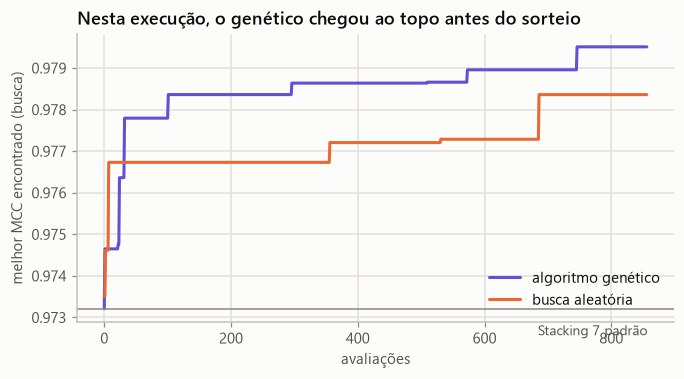

In [3]:
t0 = time.time()
apt = genetico.Aptidao(m, BUSCA)
melhor, hist = genetico.algoritmo_genetico(apt)
seq_ga = list(apt.memoria.values()); n = len(seq_ga)
seq_al = genetico.busca_aleatoria(apt, n)
print(f"{n} avaliações únicas em {time.time() - t0:.0f} s")
print(f"MCC na busca | padrão {apt(modelos.STACKING7_PADRAO):.4f} | melhor do GA {apt(melhor):.4f} | melhor da busca aleatória {max(seq_al):.4f}")
for fam, desc in modelos.descrever_stacking(melhor).items():
    print(f"  {fam:15s} {desc}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.maximum.accumulate(seq_ga), color=graficos.CATEGORICA[6], label="algoritmo genético")
ax.plot(np.maximum.accumulate(seq_al), color=graficos.CATEGORICA[1], label="busca aleatória")
ax.axhline(apt(modelos.STACKING7_PADRAO), color=graficos.TINTA_MUDA, lw=1)
ax.text(n, apt(modelos.STACKING7_PADRAO) - 0.0004, "Stacking 7 padrão", ha="right", va="top", color=graficos.TINTA_2, fontsize=9)
ax.set_xlabel("avaliações"); ax.set_ylabel("melhor MCC encontrado (busca)"); ax.legend(loc="lower right")
ax.set_title("Nesta execução, o genético chegou ao topo antes do sorteio")
graficos.mostrar(fig, "05_ga_x_aleatoria")

## Quais famílias importam? (trocando um gene por vez a partir do melhor)

In [4]:
sens = genetico.sensibilidade(apt, melhor)
print(sens.round(4).to_string(index=False))

           gene   pior  melhor  amplitude
    kNN cosseno 0.9740  0.9795     0.0055
        SVM RBF 0.9749  0.9795     0.0046
meta-modelo (C) 0.9755  0.9795     0.0040
       LightGBM 0.9763  0.9801     0.0038
            MLP 0.9760  0.9795     0.0035
 Reg. Logística 0.9772  0.9795     0.0023
    Naive Bayes 0.9778  0.9795     0.0018
    Extra Trees 0.9780  0.9795     0.0015


## A medida honesta: sementes novas
O ganho medido na própria busca é otimista: o GA escolheu o melhor entre 857 candidatos **nas mesmas 10
divisões** (a "maldição do vencedor"). As 20 divisões de confirmação usam sementes novas. Elas sorteiam outras
partições dos mesmos e-mails de desenvolvimento, o que tira o ruído da partição, mas não o da amostra. Por isso
o ganho é relatado com intervalo de confiança.

In [5]:
METODOS = {"Stacking 7 padrão": ("s", modelos.STACKING7_PADRAO), "Stacking 7 do GA (Especialista)": ("s", melhor),
           "LinearSVC padrão": ("l", modelos.LINEARSVC_PADRAO), "LinearSVC otimizado": ("l", modelos.LINEARSVC_OTIMIZADO)}
linhas = []
for c in CONF:
    yte = m.y_teste(c)
    for nome, (tipo, cfg) in METODOS.items():
        r = m.prever_stacking(cfg, c) if tipo == "s" else m.prever_linearsvc(cfg, c)
        linhas.append(dict(split=c, metodo=nome, **metricas.metricas(yte, *r)))
R = pd.DataFrame(linhas)
conf = R.groupby("metodo")[["mcc", "mcc_custo", "pr_auc", "real_lixeira_custo", "spam_passou_custo", "custo_por_mil"]].mean().loc[list(METODOS)]
print(conf.round(4).to_string())
P = R.pivot(index="split", columns="metodo", values="mcc")
GA, PD = "Stacking 7 do GA (Especialista)", "Stacking 7 padrão"
ganho_busca = apt(melhor) - apt(modelos.STACKING7_PADRAO)
ganho_novas, ic_lo, ic_hi = estatistica.ic_corrigido(P[GA], P[PD], 3310, 828)
print(f"\nganho do GA no MCC | na busca {ganho_busca:+.4f} | em sementes novas {ganho_novas:+.4f} "
      f"(IC95 corrigido {ic_lo:+.4f} a {ic_hi:+.4f})")
print(f"o ganho encolheu {1 - ganho_novas / ganho_busca:.0%} da busca para a confirmação; como o intervalo inclui zero "
      f"e inclui o ganho da busca, os dados não separam 'otimismo' de 'ganho real'")

PARES = [(GA, PD), (GA, "LinearSVC otimizado"), (PD, "LinearSVC otimizado")]
CMP = estatistica.comparar(P, PARES, 3310, 828, runs=4)
print("\nMCC (limiar 0,5):\n" + CMP[["A", "B", "dif", "p_holm", "P_A_melhor", "P_equivalentes", "P_B_melhor"]].round(4).to_string(index=False))
# no ponto de operação (limiar de custo), a métrica que decide é o custo. Para o custo, menor é melhor: comparamos B − A.
PC = R.pivot(index="split", columns="metodo", values="custo_por_mil")
CMP_CUSTO = estatistica.comparar(-PC, PARES, 3310, 828, rope=3.0, runs=4)
CMP_CUSTO["dif"] = -CMP_CUSTO["dif"]; CMP_CUSTO["t"] = -CMP_CUSTO["t"]   # sinal natural: custo de A − custo de B (negativo = A mais barato)
print("\ncusto por mil (limiar de custo; equivalência = diferença menor que 3 por mil):\n"
      + CMP_CUSTO[["A", "B", "dif", "p_holm", "P_A_melhor", "P_equivalentes", "P_B_melhor"]].round(4).to_string(index=False))

                                    mcc  mcc_custo  pr_auc  real_lixeira_custo  spam_passou_custo  custo_por_mil
metodo                                                                                                          
Stacking 7 padrão                0.9734     0.9554  0.9973              0.0041             0.0531        41.5130
Stacking 7 do GA (Especialista)  0.9744     0.9615  0.9976              0.0037             0.0456        36.6179
LinearSVC padrão                 0.9600     0.9392  0.9952              0.0048             0.0744        52.0293
LinearSVC otimizado              0.9627     0.9406  0.9956              0.0045             0.0731        50.0340

ganho do GA no MCC | na busca +0.0063 | em sementes novas +0.0010 (IC95 corrigido -0.0049 a +0.0068)
o ganho encolheu 85% da busca para a confirmação; como o intervalo inclui zero e inclui o ganho da busca, os dados não separam 'otimismo' de 'ganho real'

MCC (limiar 0,5):
                              A                

## O piso estatístico: mais sementes não resolvem
As divisões reusam os mesmos ~4100 e-mails, então o erro-padrão corrigido tem um piso. A tabela mostra a menor
diferença de MCC entre o GA e o padrão que o teste detectaria com 80% de poder (α = 5%, bilateral; quantis t).

In [6]:
dp = (P[GA] - P[PD]).std(ddof=1)
piso = pd.DataFrame([dict(folds=J, menor_dif_detectavel=estatistica.menor_diferenca_detectavel(dp, J, 828 / 3310)) for J in [5, 10, 20, 50, 100, 1000]])
print(piso.round(4).to_string(index=False))
print(f"ganho observado em 20 folds: {ganho_novas:+.4f}")

 folds  menor_dif_detectavel
     5                0.0127
    10                0.0095
    20                0.0083
    50                0.0076
   100                0.0074
  1000                0.0072
ganho observado em 20 folds: +0.0010


In [7]:
saidas.gravar("05_genetico", {
    "genetico": dict(combinacoes=int(np.prod(modelos.CARD)), avaliacoes=n, melhor=list(melhor), melhor_descricao=modelos.descrever_stacking(melhor),
                     mcc_busca_padrao=apt(modelos.STACKING7_PADRAO), mcc_busca_ga=apt(melhor), mcc_busca_aleatoria=max(seq_al),
                     ganho_busca=ganho_busca, ganho_sementes_novas=ganho_novas, ganho_sementes_novas_ic95=[ic_lo, ic_hi],
                     fracao_otimismo=1 - ganho_novas / ganho_busca,
                     fracao_otimismo_ic95=[1 - ic_hi / ganho_busca, 1 - ic_lo / ganho_busca],
                     curva_ga=np.maximum.accumulate(seq_ga).round(5), curva_aleatoria=np.maximum.accumulate(seq_al).round(5),
                     historico=hist, sensibilidade=sens, confirmacao=conf.reset_index(), comparacoes=CMP,
                     comparacoes_custo=CMP_CUSTO, piso=piso, piso_par="Stacking 7 do GA − Stacking 7 padrão", piso_poder=0.8),
}, fonte="scripts/05_algoritmo_genetico.py")
print("gravado: resultados/05_genetico.json")

gravado: resultados/05_genetico.json
